In [1]:
%pip install matplotlib numpy ipympl
%matplotlib widget

Note: you may need to restart the kernel to use updated packages.


This note book is a list of programs for learning rf im noteing what im doing and how i did it 






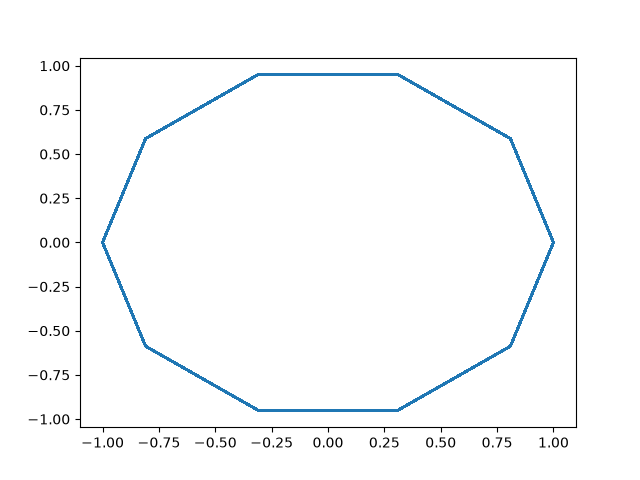

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import math

kHZ = 1e3
MHZ = 1e6
GHZ = 1e9

fs= 1000 #sampling freq
fc= 100 #carrier wave

step_Size = 1/fs 
i=0

T =np.arange(0,1,step_Size) # steps of 0 to 1  at 1/fs so nyquist in complex
#iq =np.linspace(0,step_Size,1)
i_component = np.cos(2 * np.pi * fc * T)
q_component = np.sin(2 * np.pi * fc * T)
iq = i_component + 1j * q_component
#print(iq)

plt.plot(iq.real,iq.imag)

#4096 data set
fs= 100*MHZ #sampling freq
fc= 1*GHZ #carrier wave
step_Size = 1/fs 
i=0
N =4096
T = np.arange(N) /fs
#iq =np.linspace(0,step_Size,1)
i_component = np.cos(2 * np.pi * fc * T)
q_component = np.sin(2 * np.pi * fc * T)
iq = i_component + 1j * q_component

In [3]:
# offset the carrier wave
if(len(iq) ==1000):
    fo= 100#carrier wave
    
    step_Size = 1/fs 
    i=0
    
    T =np.arange(0,1,step_Size) # steps of 0 to 1  at 1/fs so nyquist in complex
    #iq =np.linspace(0,step_Size,1)
    oi_component = np.cos(2 * np.pi * fo * T)
    oq_component = np.sin(2 * np.pi * fo * T)
    oiq = oi_component + 1j * oq_component
    
    signal = iq * oiq
    
    plt.plot(signal.real, signal.imag)

In [4]:

if(len(iq) ==1000):
    signal_fft_values = np.fft.fft(signal)
    signal_fft_power = np.abs(signal_fft_values) ** 2
    
    frequencies = np.fft.fftfreq(len(signal), d=step_Size)
    
    plt.plot(frequencies, signal_fft_power)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power")

In [5]:

iq_fft_values = np.fft.fft(iq)
iq_fft_power = np.abs(iq_fft_values) ** 2

frequencies = np.fft.fftfreq(len(iq), d=step_Size)

plt.plot(frequencies, iq_fft_power)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")


Text(21.722222222222214, 0.5, 'Power')

In [6]:
if(len(iq) ==1000):
    oiq_fft_values = np.fft.fft(oiq)
    oiq_fft_power = np.abs(oiq_fft_values) ** 2
    
    frequencies = np.fft.fftfreq(len(oiq), d=step_Size)
    
    plt.plot(frequencies, oiq_fft_power)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power")


b0: 0.0002594764347791226
b1: 0.0005189528695582452
b2: 0.0002594764347791226
a1: -0.0005188212125408376
a2: -0.0002653870809488475


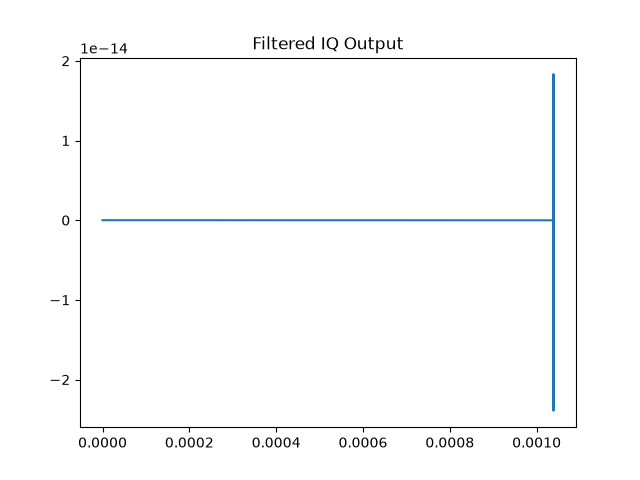

In [7]:


#filtering
#butterworth

#y[n] = b_0 x[n] + b_1 x[n-1] + b_2 x[n-2] - a_1 y[n-1] - a_2 y[n-2]
x=iq
order =2
y = np.zeros_like(x, dtype=complex) # empty output array

# prewarp
        #pi    carrier  sample
C = np.tan((3.14 * fc)/   fs)

#calculating denominator

D = pow(C,order) + math.sqrt(order)*C + 1

b0 = pow(C,order) / D
b1 = order*b0
b2 = b0
a1 = order * (pow(C, order) - 1) * b0
a2 = -(1 - math.sqrt(order) * C + pow(C, order)) * b0


print("b0:",b0)
print("b1:",b1)
print("b2:",b2)
print("a1:",a1)
print("a2:",a2)

for n in range(order,len(x)):
    y[n] = (b0 * x[n]
            + b1 * x[n-1]
            + b2 * x[n-2]
            - a1 * y[n-1]
            - a2 * y[n-2]
            )

plt.figure()
plt.plot(y.real, y.imag)
plt.title("Filtered IQ Output")

# Save as a high-resolution PNG or a scalable vector graphic (SVG)
plt.savefig("filtered_signal.png", dpi=300, bbox_inches="tight")
plt.savefig("filtered_signal.svg", bbox_inches="tight")  # Vector format

plt.show()

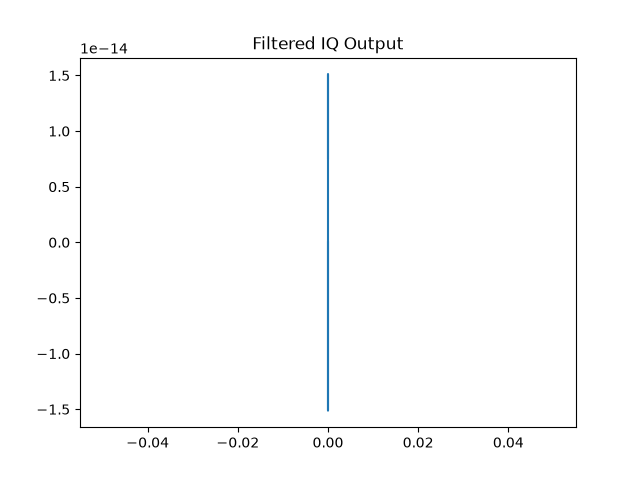

In [8]:
#high pass butterworth

K = np.tan((3.14*fc)/fs) #prewarp factor

norm = 1/1+ math.sqrt(order) *K + pow(K,2) # normalized prewarp

b0 = pow(K,order) / norm
b1 = -order*b0
b2 = b0
a1 = order * (pow(K, order) - 1) * b0
a2 = -(1 - math.sqrt(order) * K + pow(K, order)) * b0

#the feeds dont change so this for loop can be duplicated
for n in range(order,len(x)):
    y[n] = (b0 * x[n]
            + b1 * x[n-1]
            + b2 * x[n-2]
            - a1 * y[n-1]
            - a2 * y[n-2]
            )

plt.figure()
plt.plot(y.real, y.imag)
plt.title("Filtered IQ Output")

# Save as a high-resolution PNG or a scalable vector graphic (SVG)
plt.savefig("filtered_signal.png", dpi=300, bbox_inches="tight")
plt.savefig("filtered_signal.svg", bbox_inches="tight")  # Vector format

plt.show()

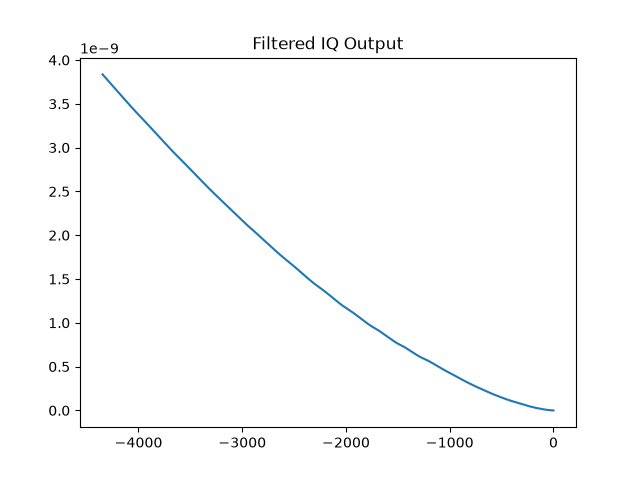

In [9]:
#band pass filter

f1=45 #lowercutoff
f2=55 #uppercutoff

Omega1 = np.tan((3.14 *f1)/fs)
Omega2 = np.tan((3.14 *f2)/fs)

B= Omega2 - Omega1 # bandwidth

Omega0 = math.sqrt(Omega1 * Omega2) # centerfreq

D = 1+B + pow(Omega0,2)

b0= B/D
B1=0.0
b2 = -b0

a1 = 2*(pow(Omega0,2) -1)/D
a2 = (1 - B +pow(Omega0,2)) /D

#the feeds dont change so this for loop can be duplicated
for n in range(order,len(x)):
    y[n] = (b0 * x[n]
            + b1 * x[n-1]
            + b2 * x[n-2]
            - a1 * y[n-1]
            - a2 * y[n-2]
            )

plt.figure()
plt.plot(y.real, y.imag)
plt.title("Filtered IQ Output")

# Save as a high-resolution PNG or a scalable vector graphic (SVG)
plt.savefig("filtered_signal.png", dpi=300, bbox_inches="tight")
plt.savefig("filtered_signal.svg", bbox_inches="tight")  # Vector format

plt.show()

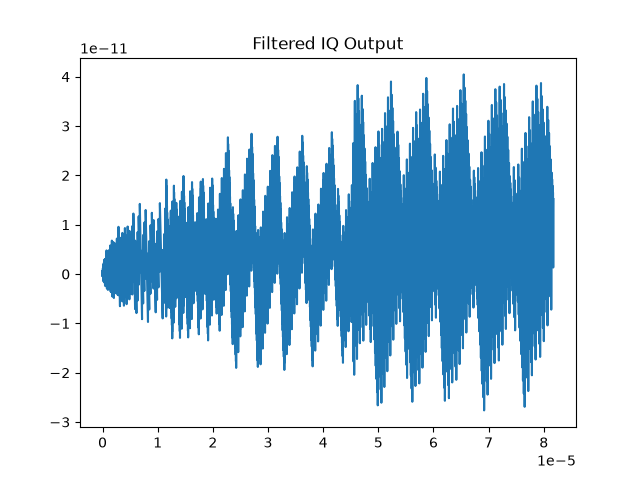

In [10]:
#band stop filter

f1=45 #lowercutoff
f2=55 #uppercutoff

Omega1 = np.tan((3.14 *f1)/fs)
Omega2 = np.tan((3.14 *f2)/fs)

B= Omega2 - Omega1 # bandwidth

Omega0 = math.sqrt(Omega1 * Omega2) # centerfreq

D = 1+B + pow(Omega0,2)


b0= (1+pow(Omega0,2))/D
b1= -2*(1 - pow(Omega0,2))/D
b2 = b0

a1 = 2*(pow(Omega0,2) -1)/D
a2 = (1 - B +pow(Omega0,2)) /D

#the feeds dont change so this for loop can be duplicated
for n in range(order,len(x)):
    y[n] = (b0 * x[n]
            + b1 * x[n-1]
            + b2 * x[n-2]
            - a1 * y[n-1]
            - a2 * y[n-2]
            )

plt.figure()
plt.plot(y.real, y.imag)
plt.title("Filtered IQ Output")

# Save as a high-resolution PNG or a scalable vector graphic (SVG)
plt.savefig("filtered_signal.png", dpi=300, bbox_inches="tight")
plt.savefig("filtered_signal.svg", bbox_inches="tight")  # Vector format

plt.show()

In [11]:
#ffts
#upto this point i used the inbuit fft functions this is the way any developer should do it but below is going to be me reimplementing it why so i can pull it appart and alter inputs to better graps whats happeing 
#(i am awful at maths so this is the best method i know to develop knowledge doing)
#used https://www.analog.com/media/en/technical-documentation/dsp-book/dsp_book_Ch12.pdf

# time domain decompositon

sig_in=[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15] # the time domain in 1 signmal many data points
#16 bit fft
#split 1
i = 0
a=0
half_len1 = len(sig_in) // 2
splt_1_sig1 = [0]*(half_len1)
splt_1_sig2 =[0]*(half_len1)
while i < (len(sig_in)-1):
    splt_1_sig1[a] = sig_in[i]
    i+=1
    splt_1_sig2[a] = sig_in[i]
    i+=1
    a+=1

print(splt_1_sig1)
print(splt_1_sig2)   
#split2
half_len2 = half_len1 // 2
splt_2_sig1 = [0]*(half_len2)
splt_2_sig2 =[0]*(half_len2)
splt_2_sig3 = [0]*(half_len2)
splt_2_sig4 =[0]*(half_len2)
i = 0
a=0
while i < (len(splt_1_sig1)-1):
    splt_2_sig1[a] = splt_1_sig1[i] 
    splt_2_sig3[a] = splt_1_sig2[i]
    i+=1
    splt_2_sig2[a] = splt_1_sig1[i] 
    splt_2_sig4[a] = splt_1_sig2[i]
    i+=1
    a+=1

print(splt_2_sig1)
print(splt_2_sig2) 
print(splt_2_sig3)
print(splt_2_sig4) 

#split3
half_len3 = half_len2 // 2
splt_3_sig1 = [0]*(half_len3)
splt_3_sig2 =[0]*(half_len3)
splt_3_sig3 = [0]*(half_len3)
splt_3_sig4 =[0]*(half_len3)
splt_3_sig5 = [0]*(half_len3)
splt_3_sig6 =[0]*(half_len3)
splt_3_sig7 = [0]*(half_len3)
splt_3_sig8 =[0]*(half_len3)
i = 0
a=0
while i < (len(splt_2_sig1)-1):
    splt_3_sig1[a] = splt_2_sig1[i]
    splt_3_sig3[a] = splt_2_sig2[i]
    splt_3_sig5[a] = splt_2_sig3[i]
    splt_3_sig7[a] = splt_2_sig4[i]
    i+=1
    splt_3_sig2[a] = splt_2_sig1[i]
    splt_3_sig4[a] = splt_2_sig2[i]
    splt_3_sig6[a] = splt_2_sig3[i]
    splt_3_sig8[a] = splt_2_sig4[i]
    i+=1
    a+=1

print(splt_3_sig1)
print(splt_3_sig2) 
print(splt_3_sig3)
print(splt_3_sig4) 
print(splt_3_sig5)
print(splt_3_sig6) 
print(splt_3_sig7)
print(splt_3_sig8) 

#split4
half_len4 = half_len3 // 2
splt_4_sig1 = [0]*(half_len4)
splt_4_sig2 =[0]*(half_len4)
splt_4_sig3 = [0]*(half_len4)
splt_4_sig4 =[0]*(half_len4)
splt_4_sig5 = [0]*(half_len4)
splt_4_sig6 =[0]*(half_len4)
splt_4_sig7 = [0]*(half_len4)
splt_4_sig8 =[0]*(half_len4)
splt_4_sig9 = [0]*(half_len4)
splt_4_sig10 =[0]*(half_len4)
splt_4_sig11 = [0]*(half_len4)
splt_4_sig12 =[0]*(half_len4)
splt_4_sig13 = [0]*(half_len4)
splt_4_sig14 =[0]*(half_len4)
splt_4_sig15 = [0]*(half_len4)
splt_4_sig16 =[0]*(half_len4)
i = 0
a=0
while i < (len(splt_3_sig1)-1):
    splt_4_sig1[a] = splt_3_sig1[i]
    splt_4_sig3[a] = splt_3_sig2[i]
    splt_4_sig5[a] = splt_3_sig3[i]
    splt_4_sig7[a] = splt_3_sig4[i]
    splt_4_sig9[a] = splt_3_sig5[i]
    splt_4_sig11[a] = splt_3_sig6[i]
    splt_4_sig13[a] = splt_3_sig7[i]
    splt_4_sig15[a] = splt_3_sig8[i]
    i+=1
    splt_4_sig2[a] = splt_3_sig1[i]
    splt_4_sig4[a] = splt_3_sig2[i]
    splt_4_sig6[a] = splt_3_sig3[i]
    splt_4_sig8[a] = splt_3_sig4[i]
    splt_4_sig10[a] = splt_3_sig5[i]
    splt_4_sig12[a] = splt_3_sig6[i]
    splt_4_sig14[a] = splt_3_sig7[i]
    splt_4_sig16[a] = splt_3_sig8[i]
    i+=1
    a+=1
#16 signal;s 1 point
print(splt_4_sig1)
print(splt_4_sig2) 
print(splt_4_sig3)
print(splt_4_sig4) 
print(splt_4_sig5)
print(splt_4_sig6) 
print(splt_4_sig7)
print(splt_4_sig8) 
print(splt_4_sig9)
print(splt_4_sig10) 
print(splt_4_sig11)
print(splt_4_sig12) 
print(splt_4_sig13)
print(splt_4_sig14) 
print(splt_4_sig15)
print(splt_4_sig16) 


[0, 2, 4, 6, 8, 10, 12, 14]
[1, 3, 5, 7, 9, 11, 13, 15]
[0, 4, 8, 12]
[2, 6, 10, 14]
[1, 5, 9, 13]
[3, 7, 11, 15]
[0, 8]
[4, 12]
[2, 10]
[6, 14]
[1, 9]
[5, 13]
[3, 11]
[7, 15]
[0]
[8]
[4]
[12]
[2]
[10]
[6]
[14]
[1]
[9]
[5]
[13]
[3]
[11]
[7]
[15]


In [12]:
# ai solution to the above longwinded deomposition
sig_in = [0] * 1000
#find the fft size closest to the data set (in hardware we would do similar,split data or even just drop the data )
n_padded = 2 ** math.ceil(math.log2(len(sig_in)))
#zero pad the data (this can be done for cpu systems not for fpga systems)
sig_padded = list(sig_in) + [0] * (n_padded - len(sig_in))

n = len(sig_padded)
bits = int(math.log2(n))

# split the signal into its component interlaced decomposition
reordered_indices = []
for i in range(n):
    rev = int(bin(i)[2:].zfill(bits)[::-1], 2)
    reordered_indices.append(rev)
    
decomposed_signals = [[sig_padded[i]] for i in reordered_indices]
    
print(f"Original IQ size: {len(sig_in)} | Padded FFT size: {n}")
print(f"Total decomposed signals: {len(decomposed_signals)}")

Original IQ size: 1000 | Padded FFT size: 1024
Total decomposed signals: 1024


In [13]:
#sig_in = iq
sig_in =iq
#find the fft size closest to the data set (in hardware we would do similar,split data or even just drop the data )
n_padded = 2 ** math.ceil(math.log2(len(sig_in)))
#zero pad the data (this can be done for cpu systems not for fpga systems)
sig_padded = list(sig_in) + [0] * (n_padded - len(sig_in))

n = len(sig_padded)
bits = int(math.log2(n))

# split the signal into its component interlaced decomposition
reordered_indices = []
for i in range(n):
    rev = int(bin(i)[2:].zfill(bits)[::-1], 2)
    reordered_indices.append(rev)
    
decomposed_signals = [[sig_padded[i]] for i in reordered_indices]
    
print(f"Original IQ size: {len(sig_in)} | Padded FFT size: {n}")
print(f"Total decomposed signals: {len(decomposed_signals)}")



Original IQ size: 4096 | Padded FFT size: 4096
Total decomposed signals: 4096


In [14]:
# frequency syntehsis ? (butterfly stage nocertin why called that)


splt_3_sigs = [
    splt_3_sig1, splt_3_sig2, splt_3_sig3, splt_3_sig4,
    splt_3_sig5, splt_3_sig6, splt_3_sig7, splt_3_sig8
]

i=0
#splt3 1 ->4
fd1 = [0] *8
for i in range(8):
    fd1[i] = splt_3_sigs[i]
    
print("fd1:", fd1)
#splt3 5->8

i=0
fd2 = [0] *8
#obtain  angle

N = 8 # combining the 2 4 point blocks




half_n = len(fd1) //2

for k in range(4):
     #k  index of freq bin
    A =fd1[k]
    B =fd1[k +half_n]
    
    theta = -2 * math.pi * k /N

    #twidle factor (yes actualy called that and i will say i hate it)
    W = math.cos(theta) +1j * math.sin(theta) # didnt go over this earlier 1j means its complex data so i and q
    
    # butter fly out 
    val_A = A[0] if isinstance(A, list) else A
    val_B = B[0] if isinstance(B, list) else B
    
    out_top = val_A + (val_B * W)
    out_bottom = val_A - (val_B * W)
    fd2[k] = out_top
    fd2[k + half_n] = out_bottom

print("fd2:", fd2)

fd1: [[0, 8], [4, 12], [2, 10], [6, 14], [1, 9], [5, 13], [3, 11], [7, 15]]
fd2: [(1+0j), (7.535533905932738-3.5355339059327373j), (2-3j), (1.0502525316941682-4.949747468305833j), (-1+0j), (0.46446609406726225+3.5355339059327373j), (1.9999999999999998+3j), (10.949747468305832+4.949747468305833j)]


In [15]:
# modular method
#tested against refrences from numpt
numpy_reference = np.fft.fft(sig_padded)
fd1 = list(decomposed_signals)
#print("fd1:", fd1)
#splt3 5->8

i=1

#obtain  angle

N = len(fd1) 
fd2 = list(fd1)
half_n = 1
while half_n < N:
    # loop last stage into next
    prev_stage = list(fd2)

    for j in range(0,N,half_n * 2):
            #print(half_n)
            for k in range(half_n):
                idx1 = j + k
                idx2 = j + k + half_n
                    
                 #k  index of freq bin
                A =prev_stage[idx1]
                B =prev_stage[idx2]
                #single loop theta
                #theta = -2 * math.pi * k /N
                #repetative loop theta
                theta = -2 * math.pi * k / (half_n * 2)
                #twidle factor (yes actualy called that and i will say i hate it)
                W = math.cos(theta) +1j * math.sin(theta) # didnt go over this earlier 1j means its complex data so i and q
                
                # butter fly out 
                val_A = A[0] if isinstance(A, list) else A
                val_B = B[0] if isinstance(B, list) else B
                
                out_top = val_A + (val_B * W)
                out_bottom = val_A - (val_B * W)
                fd2[idx1] = out_top
                fd2[idx2] = out_bottom
    half_n *= 2

fd2_arr = np.array(fd2)

Max difference from NumPy: 4.2178100846735214e-24


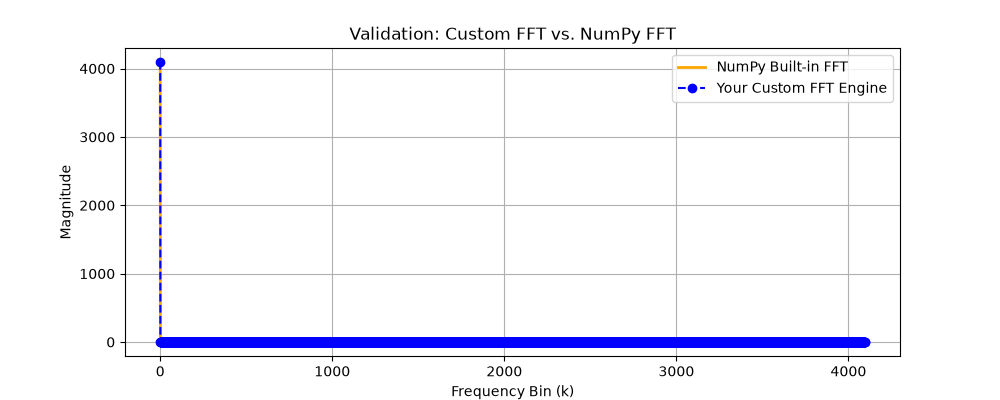

In [16]:

max_diff = np.max(np.abs(numpy_reference[:len(fd2_arr)] - fd2_arr))
print(f"Max difference from NumPy: {max_diff}")
plt.figure(figsize=(10, 4))
plt.plot(np.abs(numpy_reference), label="NumPy Built-in FFT", color="orange", linewidth=2)
plt.plot(np.abs(fd2_arr), label="Your Custom FFT Engine", color="blue", linestyle="--", marker="o")
plt.title("Validation: Custom FFT vs. NumPy FFT")
plt.xlabel("Frequency Bin (k)")
plt.ylabel("Magnitude")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
#mixer
#angle theta (this is used lots so while im duplicating it i would assume for an actual application set it as a variable that is defined once to reduce memory)
theta = 2 * np.pi * fc * T

# full formula
osc_real = np.cos(theta)
osc_imag = -1j * np.sin(theta)
local_oscillator_long = osc_real + osc_imag
#this can be done in numpy with
local_oscillator_short = np.exp(-1j * theta)

max_difference = np.max(np.abs(local_oscillator_long - local_oscillator_short))

print(f"Max difference between long-hand and short-hand: {max_difference}")

iq_base_band = iq* local_oscillator_long
print("iq_base_band:", iq_base_band)
print("iq:", iq)

Max difference between long-hand and short-hand: 0.0
iq_base_band: [1.+0.j 1.+0.j 1.+0.j ... 1.+0.j 1.+0.j 1.+0.j]
iq: [1.+0.00000000e+00j 1.-2.44929360e-15j 1.-4.89858720e-15j ...
 1.+6.53068705e-12j 1.-8.69158765e-12j 1.+5.18996811e-12j]


In [18]:
# antialiasing filter
cutoff_bin = len(iq) // 4
aliased_iq = list(iq)
for k in range(cutoff_bin, len(aliased_iq) - cutoff_bin):
    aliased_iq[k] = 0.0

In [19]:
#fft again full implmentation
sig_in =aliased_iq
#find the fft size closest to the data set (in hardware we would do similar,split data or even just drop the data )
n_padded = 2 ** math.ceil(math.log2(len(sig_in)))
#zero pad the data (this can be done for cpu systems not for fpga systems)
sig_padded = list(sig_in) + [0] * (n_padded - len(sig_in))

n = len(sig_padded)
bits = int(math.log2(n))

# split the signal into its component interlaced decomposition
reordered_indices = []
for i in range(n):
    rev = int(bin(i)[2:].zfill(bits)[::-1], 2)
    reordered_indices.append(rev)
    
decomposed_signals = [[sig_padded[i]] for i in reordered_indices]
    
print(f"Original IQ size: {len(sig_in)} | Padded FFT size: {n}")
print(f"Total decomposed signals: {len(decomposed_signals)}")

splt_3_sigs = [
    splt_3_sig1, splt_3_sig2, splt_3_sig3, splt_3_sig4,
    splt_3_sig5, splt_3_sig6, splt_3_sig7, splt_3_sig8
]

i=0
#splt3 1 ->4
fd1 = [0] *8
for i in range(8):
    fd1[i] = splt_3_sigs[i]
    
print("fd1:", fd1)

# modular method
#tested against refrences from numpt
numpy_reference = np.fft.fft(sig_padded)
fd1 = list(decomposed_signals)
#print("fd1:", fd1)
#splt3 5->8

i=1

#obtain  angle

N = len(fd1) 
fd2 = list(fd1)
half_n = 1
while half_n < N:
    # loop last stage into next
    prev_stage = list(fd2)

    for j in range(0,N,half_n * 2):
            #print(half_n)
            for k in range(half_n):
                idx1 = j + k
                idx2 = j + k + half_n
                    
                 #k  index of freq bin
                A =prev_stage[idx1]
                B =prev_stage[idx2]
                #single loop theta
                #theta = -2 * math.pi * k /N
                #repetative loop theta
                theta = -2 * math.pi * k / (half_n * 2)
                #twidle factor (yes actualy called that and i will say i hate it)
                W = math.cos(theta) +1j * math.sin(theta) # didnt go over this earlier 1j means its complex data so i and q
                
                # butter fly out 
                val_A = A[0] if isinstance(A, list) else A
                val_B = B[0] if isinstance(B, list) else B
                
                out_top = val_A + (val_B * W)
                out_bottom = val_A - (val_B * W)
                fd2[idx1] = out_top
                fd2[idx2] = out_bottom
    half_n *= 2

fd2_arr = np.array(fd2)

Original IQ size: 4096 | Padded FFT size: 4096
Total decomposed signals: 4096
fd1: [[0, 8], [4, 12], [2, 10], [6, 14], [1, 9], [5, 13], [3, 11], [7, 15]]


Max difference from NumPy: 9.301448500309561e-13


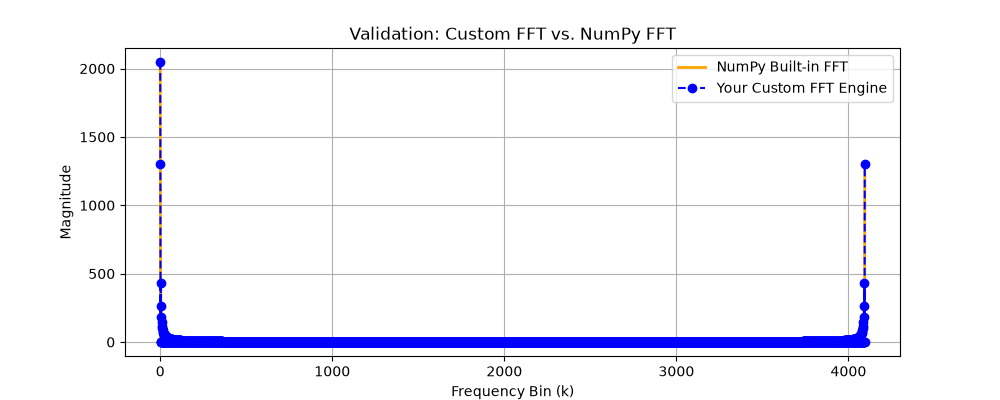

In [20]:
#diffrence 
max_diff = np.max(np.abs(numpy_reference[:len(fd2_arr)] - fd2_arr))
print(f"Max difference from NumPy: {max_diff}")
plt.figure(figsize=(10, 4))
plt.plot(np.abs(numpy_reference), label="NumPy Built-in FFT", color="orange", linewidth=2)
plt.plot(np.abs(fd2_arr), label="Your Custom FFT Engine", color="blue", linestyle="--", marker="o")
plt.title("Validation: Custom FFT vs. NumPy FFT")
plt.xlabel("Frequency Bin (k)")
plt.ylabel("Magnitude")
plt.legend()
plt.grid(True)
plt.show()
# this output wrapss round as 0 and max are next to eachother sort of 

In [23]:
# fft shift this places 1 and max next to eachother

N = len(fd2_arr)
mid = N //2
first_half = fd2_arr[:mid]
second_half = fd2_arr[mid:]

custom_shifted = list(second_half) + list(first_half)

numpy_shifted = np.fft.fftshift(fd2_arr)


Max difference from NumPy: 0.0


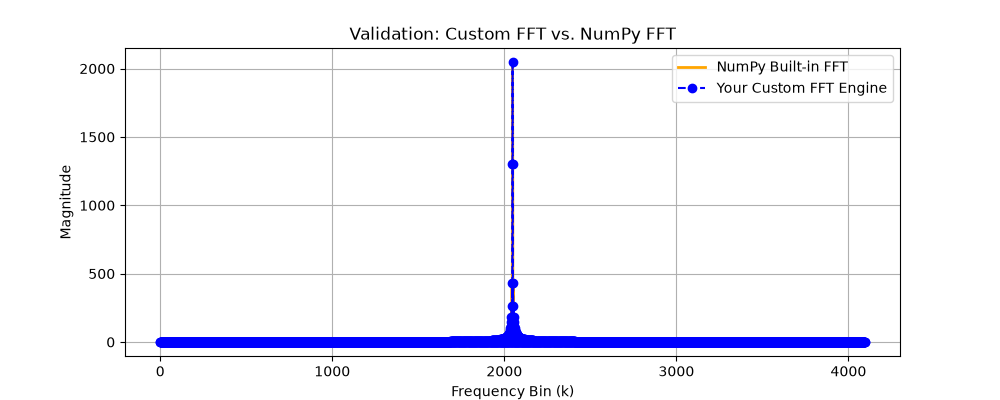

In [24]:
max_diff = np.max(np.abs(np.array(custom_shifted) - numpy_shifted))
print(f"Max difference from NumPy: {max_diff}")
plt.figure(figsize=(10, 4))
plt.plot(np.abs(numpy_shifted), label="NumPy Built-in FFT", color="orange", linewidth=2)
plt.plot(np.abs(custom_shifted), label="Your Custom FFT Engine", color="blue", linestyle="--", marker="o")
plt.title("Validation: Custom FFT vs. NumPy FFT")
plt.xlabel("Frequency Bin (k)")
plt.ylabel("Magnitude")
plt.legend()
plt.grid(True)
plt.show()